In [1]:
#Model checks
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np
from pathlib import Path
import pandas as pd
import argparse
import os
import glob
import re
import sys

sys.path.append("../../model-fit-tools")
from model_fit_tools.model_comparison import  calculate_confusion_and_inversion
from model_fit_tools.plotting import plot_matrices

In [2]:
print(sys.version)

3.10.8 (main, Oct 13 2022, 09:48:40) [Clang 14.0.0 (clang-1400.0.29.102)]


This script shows model and parameter recovery for both MDP and GP models

### MDP models

In [2]:
def create_recovery_matrix(recovery_df):
    confusion = pd.crosstab(recovery_df['true_model'], recovery_df['best_fit_model'], normalize='index')
    return confusion.round(2)

#select models to compare
mchecks = ["baseline", "weighted", "pessimistic"]

/Users/verra/Documents/AVGEN_pub/fitted/mdp_modelrecovery
Loaded 400 files, total rows: 400
best_fit_model  baseline  gen_beliefs  pessimistic
true_model                                        
baseline            1.00         0.00          0.0
gen_beliefs         0.15         0.75          0.1
pessimistic         0.00         0.00          1.0


<Axes: xlabel='best_fit_model', ylabel='true_model'>

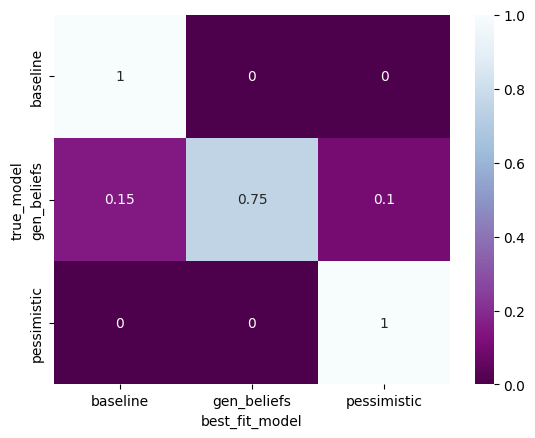

In [ ]:
#MDP
#Model recovery 

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../.."))

directory = os.path.join(parent_dir, "fitted/mdp_modelrecovery")
print(directory)

# get fits
csv_files = glob.glob(os.path.join(directory, "*.csv"))
df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)

print(f"Loaded {len(csv_files)} files, total rows: {len(df)}")



fdf = df[df[["true_model"]].isin(mchecks).all(axis=1)]
cols_to_keep = ["true_model"] + [c for c in mchecks if c in fdf.columns]
subset_df = fdf[cols_to_keep].copy()
subset_df["best_fit_model"] = subset_df[mchecks].idxmin(axis=1)

subset_df["true_model"] = subset_df["true_model"].replace("weighted", "gen_beliefs")
subset_df["best_fit_model"] = subset_df["best_fit_model"].replace("weighted", "gen_beliefs")



confusion_matrix = create_recovery_matrix(subset_df)
print(confusion_matrix)
confusion_df = pd.DataFrame(confusion_matrix)
sns.heatmap(confusion_df, annot=True, cmap="BuPu_r")

/Users/verra/Documents/AVGEN_pub/fitted/mdp_parameterrecovery
Loaded 410 files, total rows: 84750


/opt/homebrew/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
/var/folders/3q/315fpymx2zdc6gr50f3yzz6w0000gq/T/ipykernel_51005/3974440173.py:51: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


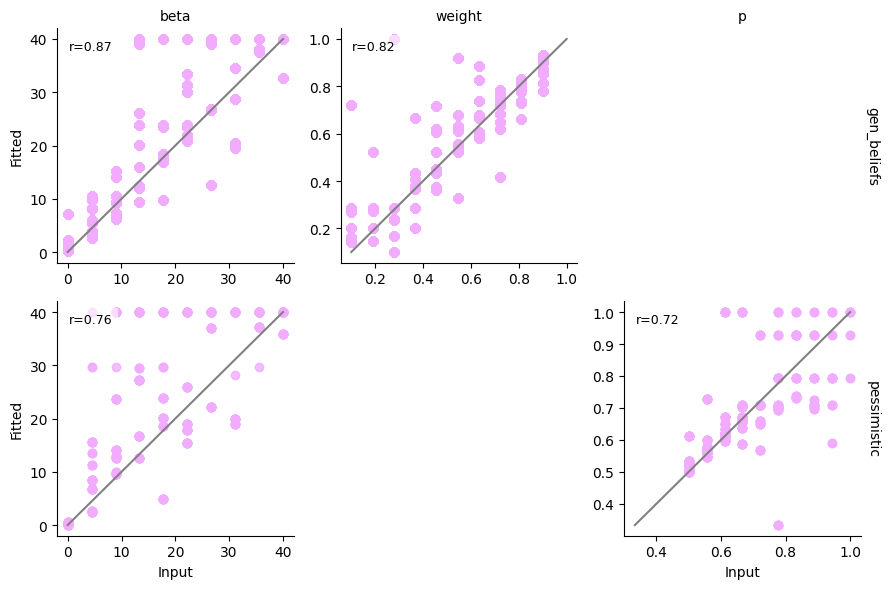

In [ ]:
#Parameter recovery 

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../.."))
directory = os.path.join(parent_dir, "fitted/mdp_parameterrecovery")
print(directory)

csv_files = glob.glob(os.path.join(directory, "*.csv"))
df = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)
print(f"Loaded {len(csv_files)} files, total rows: {len(df)}")

df_subset = df[df["model"].isin(mchecks)].copy()
params = ["beta", "weight", "p"]

# long format
plot_data = []
for param in params:
    input_col = f"input_{param}"
    fitted_col = f"fitted_{param}"
    if input_col in df_subset.columns and fitted_col in df_subset.columns:
        temp = df_subset[["model", input_col, fitted_col]].copy()
        temp = temp.rename(columns={input_col: "input", fitted_col: "fitted"})
        temp["parameter"] = param
        plot_data.append(temp)

plot_df = pd.concat(plot_data, ignore_index=True)

plot_df.loc[plot_df["model"] == "weighted", "model"] = "gen_beliefs"

g = sns.FacetGrid(plot_df, row="model", col="parameter", margin_titles=True,sharex=False, sharey=False)


def scatter_with_corr(data, color, **kwargs):
    ax = plt.gca()
    if data["input"].notna().any() and data["fitted"].notna().any():
        ax.scatter(data["input"], data["fitted"], color='#f1abffff', alpha=0.8)
        min_val = min(data[["input","fitted"]].min())
        max_val = max(data[["input","fitted"]].max())
        ax.plot([min_val, max_val], [min_val, max_val], ls="-", c="gray")

        # correlation
        if len(data.dropna()) > 1:
            r, _ = pearsonr(data["input"], data["fitted"])
            ax.text(0.05, 0.95, f"r={r:.2f}", transform=ax.transAxes,
                    ha="left", va="top", fontsize=9, bbox=dict(facecolor="white", alpha=0.6, edgecolor="none"))
    else:
        ax.set_axis_off()

g.map_dataframe(scatter_with_corr)
g.set_axis_labels("Input", "Fitted")
g.set_titles(row_template="{row_name}", col_template="{col_name}")
plt.tight_layout()
plt.show()

### GP models

Loaded 80 files for '60', total rows: 320
Loaded 80 files for '70', total rows: 320
Loaded 80 files for '80', total rows: 320
Loaded 80 files for '90', total rows: 320
['euc_rbf_peak' 'euc_lin_peak']


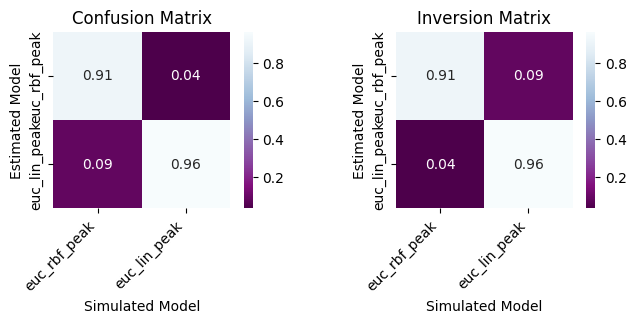

In [5]:
#GP models 

#Parameter recovery 
parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../.."))
directory = os.path.join(parent_dir, "fitted/ls_modelrecovery_peak")
csv_files = glob.glob(os.path.join(directory, "*.csv"))

def load_matching_files(target):
    pattern = re.compile(rf"_[0-9]+_{target}_")  # e.g. "_12_60_" matches 60 at 2nd position
    matched_files = [f for f in csv_files if pattern.search(os.path.basename(f))]
    
    if matched_files:
        df = pd.concat((pd.read_csv(f) for f in matched_files), ignore_index=True)
        print(f"Loaded {len(matched_files)} files for '{target}', total rows: {len(df)}")
        return df
    else:
        print(f"No files found for '{target}'")
        return pd.DataFrame()

# Load into separate DataFrames
df60 = load_matching_files("60")
df70 = load_matching_files("70")
df80 = load_matching_files("80")
df90 = load_matching_files("90")

dfs = [df for df in [df60, df70, df80, df90] if not df.empty]
processed_dfs = []

for df in dfs:
    model_recovery_df = df[['SIM', 'FIT', 'ID', 'EWAIC']].copy()
    model_recovery_df.columns = ['simulated_model', 'estimation_model', 'iteration', 'waic']
    processed_dfs.append(model_recovery_df)

df_all = pd.concat(processed_dfs, ignore_index=True)
subset_df = df_all[
    df_all["simulated_model"].isin(["euc_rbf_peak", "euc_lin_peak"]) &
    df_all["estimation_model"].isin(["euc_rbf_peak", "euc_lin_peak"])
]
subset_df = (
    subset_df
    .sort_values(by=["iteration", "simulated_model"], ascending=[True, True])
    .reset_index(drop=True)
)
subset_df['iteration'] = np.tile(np.arange(0, 80, 1).repeat(2), 2)


confusion_matrix, inversion_matrix = calculate_confusion_and_inversion(subset_df)

plot_matrices(confusion_matrix,inversion_matrix,['euc_rbf_peak', 'euc_lin_peak'],cmap="BuPu_r")

In [6]:
parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../.."))
directory = os.path.join(parent_dir, "fitted/ls_parameterrecovery_peak")

# Find all CSV files in that directory
csv_files = glob.glob(os.path.join(directory, "*.csv"))

# Read and append all CSVs into one DataFrame
dfrec = pd.concat((pd.read_csv(f) for f in csv_files), ignore_index=True)
print(dfrec)
print(f"Loaded {len(csv_files)} files, total rows: {len(dfrec)}")

      recovered    ls  recovered_peak  peak    model
0      0.848853  0.01       68.685738  80.0  euc_lin
1      0.848853  0.06       68.685738  80.0  euc_lin
2      0.848853  0.11       68.685738  80.0  euc_lin
3      0.848853  0.16       68.685738  80.0  euc_lin
4      0.848853  0.21       68.685738  80.0  euc_lin
...         ...   ...             ...   ...      ...
2275   5.769345  5.76       69.962738  70.0  euc_lin
2276   5.819105  5.81       69.964996  70.0  euc_lin
2277   5.869839  5.86       69.968544  70.0  euc_lin
2278   5.920647  5.91       69.956207  70.0  euc_lin
2279   5.968877  5.96       69.967751  70.0  euc_lin

[2280 rows x 5 columns]
Loaded 19 files, total rows: 2280


/opt/homebrew/lib/python3.10/site-packages/seaborn/axisgrid.py:123: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


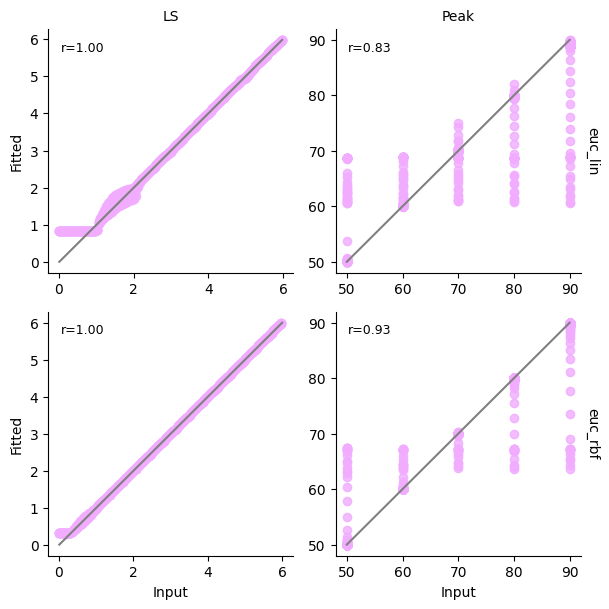

In [ ]:
dfrec_sub = dfrec
dfrec_sub = dfrec_sub[
    dfrec_sub["model"].isin(["euc_rbf", "euc_lin"])
]


df_long = pd.concat(
    [
        dfrec_sub[["model", "ls", "recovered"]]
        .rename(columns={"ls": "input", "recovered": "fitted"})
        .assign(parameter="LS"),

        dfrec_sub[["model", "peak", "recovered_peak"]]
        .rename(columns={"peak": "input", "recovered_peak": "fitted"})
        .assign(parameter="Peak"),
    ],
    ignore_index=True
)

g = sns.FacetGrid(df_long, row="model", col="parameter", margin_titles=True,sharex=False, sharey=False)
g.map_dataframe(scatter_with_corr)
g.set_axis_labels("Input", "Fitted")
g.set_titles(row_template="{row_name}", col_template="{col_name}")